In [1]:
from math import pi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
from scipy.integrate import trapezoid
from tqdm import tqdm
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/hn2016_falwa/src/falwa/")
from wrapper import barotropic_input_qref_to_compute_lwa

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + 20, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
def compute_dw_stat_lwa(dw_qgpv,dw_qref):
   # --- Parameters --- #
    Earth_radius = 6.378e+6 # Earth's radius
    # --- Read in longitude and latitude arrays --- #
    lon = dw_qgpv.lon.values
    lat = dw_qgpv.lat.values
    clat = np.abs(np.cos(lat*pi/180.)) # cosine latitude
    nlon = lon.size
    nlat = lat.size
    
    # --- Parameters needed to use the module HN2015_LWA --- 
    dphi = (lat[2]-lat[1])*pi/180. # Equal spacing between latitude grid points, in radian
    area = 2.*pi*Earth_radius**2 *(np.cos(lat[:,np.newaxis]*pi/180.)*dphi)/float(nlon) * np.ones((nlat,nlon))
    area = np.abs(area) # To make sure area element is always positive (given floating point errors).
    
    # --- Read in the absolute vorticity field from the netCDF file --- #
    density_weighted_qgpv = dw_qgpv.mean('time')
    density_weighted_qref = dw_qref.mean('time')
    
    return barotropic_input_qref_to_compute_lwa(ylat=lat, qref=density_weighted_qref, vort=density_weighted_qgpv, area=area, dmu=Earth_radius*clat*dphi)[0]

def bootstrap_dw_stat_lwa(dw_qgpv,dw_qref,n_iterations,n_sample):
    length = len(dw_qgpv)
    dw_stat_lwa_set = []
    for n in tqdm(range(n_iterations)):
        idxs = np.random.choice(np.arange(0,length,1),size=n_sample,replace=False)
        dw_stat_lwa_set.append(compute_dw_stat_lwa(dw_qgpv,dw_qref))
    dw_stat_lwa_set_nparr = np.array(dw_stat_lwa_set)
    return dw_stat_lwa_set_nparr.std(axis=0)*(np.sqrt(n_sample)/np.sqrt(len(dw_qgpv)))            

In [4]:
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/
#!cdo -monmean -selvar,dw_qgpv,dw_qref -mergetime falwa_output/*.nc tot/dwqgpv_dwqref_monthly_2-51.nc

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90


In [5]:
#import climatology
ds = xr.open_dataset('tot/dwqgpv_dwqref_monthly_2-51.nc')#.sel(lat=slice(0,90))
#ds = flip_and_append(ds)

In [6]:
dw_qgpv = ds['dw_qgpv']
dw_qref = ds['dw_qref']
density_weighted_stat_lwa = compute_dw_stat_lwa(dw_qgpv,dw_qref)
density_weighted_stat_lwa_std = bootstrap_dw_stat_lwa(dw_qgpv,dw_qref,n_iterations=50,n_sample=12)

100%|██████████| 50/50 [00:18<00:00,  2.65it/s]


In [7]:
#zonally symmetric correction
ds_symmetric = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_KS_30_72,90/tot/dw_stat_lwa_2-51.nc')
density_weighted_stat_lwa_symmetric = ds_symmetric['dw_stat_lwa']
density_weighted_stat_lwa = density_weighted_stat_lwa-density_weighted_stat_lwa_symmetric

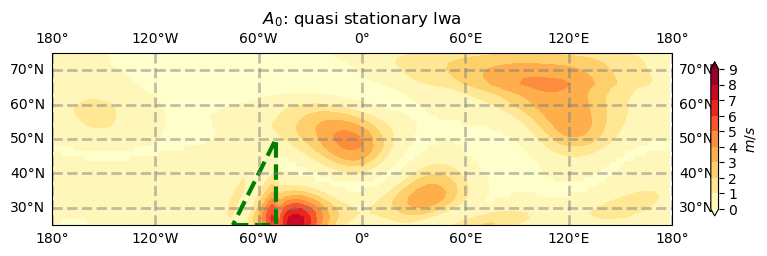

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

lon = ds['lon']
lat = ds['lat']

# Plot the filled contours
contour = ax.contourf(
    lon,lat,density_weighted_stat_lwa,
    levels=np.arange(0, 10, 1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(2)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False
gl.ylabels_right = False

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$A_0$: quasi stationary lwa')

plt.show()

In [9]:
density_weighted_stat_lwa_DA = dw_qgpv[0,:,:].copy() #shortcut to initialize the data_array
density_weighted_stat_lwa_DA.values = density_weighted_stat_lwa 

#same for the error:
density_weighted_stat_lwa_std_DA = density_weighted_stat_lwa_DA.copy()
density_weighted_stat_lwa_std_DA.values = density_weighted_stat_lwa_std

In [10]:
density_weighted_stat_lwa_DA.name = 'dw_stat_lwa'
ds_output = density_weighted_stat_lwa_DA.to_dataset()
ds_output['dw_stat_lwa_std'] = density_weighted_stat_lwa_std_DA
ds_output.to_netcdf('tot/dw_stat_lwa_2-51.nc')